# Tarea 2 Optimización

Implementación en `gurobipy` de una versión reducida del *Consistent Vehicle Routing Problem* de Campelo, Neves-Moreira, Amorim y Almada-Lobo (2019), *EJOR* 273(1), 131–145.

### Integrantes

- Sofía Ignacia López Aguilera
- Jhostian Matías San Martín Morales
- Diego Emilio Rebollo García


### Contenido
1. Configuración
2. Instancias: formato, lectura y validación
3. Generación de instancias desde Solomon (CVRPLIB)
4. Modelo matemático e implementación
5. Lectura y validación de la solución
6. Ejecución: instancias de la entrega
7. Experimentos
8. Resumen de resultados
9. Discusión

## 1. Configuración

In [1]:
# %pip install gurobipy

In [2]:
import json
import math
import random
from dataclasses import dataclass, field
from pathlib import Path

import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt

CARPETA = Path("instancias")
ENV = None
# ENV = gp.Env(params={"WLSACCESSID": "...", "WLSSECRET": "...", "LICENSEID": 0})

## 2. Instancias: formato, lectura y validación

Cada instancia es un JSON con el formato de `contrato_instancias.md`. Con esos datos se arman los conjuntos y parámetros del modelo:

| Símbolo | En el código | Descripción |
|---|---|---|
| $\mathcal{D}$ | `D` | Días $\{0,\dots,\lvert\mathcal{D}\rvert-1\}$ |
| $\mathcal{R}$ | `R` | Rutas (vehículos/conductores) |
| $\mathcal{N}_C$ | `C` | Clientes $\{1,\dots,n\}$ |
| $0,\ n+1$ | `salida`, `regreso` | Depósito como nodo de salida y de regreso (mismas coordenadas) |
| $\mathcal{O}$ | `O` | Pedidos $(i,t)$: el cliente $i$ pide el día $t$ |
| $\mathcal{N}_{TW}$, $[a_i,b_i]$ | `ventana` | Clientes con ventana de tiempo |
| $[a_W,b_W]$ | `aW`, `bW` | Horario del depósito |
| $Q$, $q_{it}$, $st_{it}$ | `Q`, `q`, `st` | Capacidad, demanda y tiempo de servicio |
| $td_{ij}$, $tt_{ij}$ | `td`, `tt` | Distancia euclidiana (sin redondeo) y tiempo $tt_{ij} = td_{ij}/\text{velocidad}$ |

**Ventana efectiva:** Para calcular los Big-M y filtrar arcos, a un cliente sin ventana se le asigna la del depósito: $[a_i,b_i] = [a_W,b_W]$ si $i \notin \mathcal{N}_{TW}$. Los métodos `a(i)` y `b(i)` devuelven esa ventana.

Validaciones de `cargar_instancia()` (la instancia no se carga si falla alguna):
1. Los ids de clientes son $1,\dots,n$, consecutivos.
2. Cada pedido referencia un cliente y un día existentes.
3. No hay pedidos duplicados $(i,t)$.
4. Todo cliente tiene al menos un pedido.
5. $q_{it} \le Q$.
6. $a_i \le b_i$.
7. Cada pedido es atendible en una ruta exclusiva: con $\underline{w}_i = \max(a_i,\ a_W + tt_{0i})$, se exige $\underline{w}_i \le b_i$ y $\underline{w}_i + st_{it} + tt_{i,n+1} \le b_W$.


In [3]:
@dataclass
class Instancia:
    nombre: str
    D: list
    R: list
    C: list
    salida: int
    regreso: int
    O: list
    ventana: dict
    aW: float
    bW: float
    Q: float
    q: dict
    st: dict
    td: dict
    tt: dict
    A: list = field(default_factory=list)
    coord: dict = field(default_factory=dict)

    def a(self, i):
        return self.ventana[i][0] if i in self.ventana else self.aW

    def b(self, i):
        return self.ventana[i][1] if i in self.ventana else self.bW


def cargar_instancia(ruta) -> Instancia:
    with open(ruta, encoding="utf-8") as f:
        data = json.load(f)

    n = len(data["clientes"])
    C = [c["id"] for c in data["clientes"]]
    if C != list(range(1, n + 1)):
        raise ValueError("Los ids de clientes deben ser 1..n, consecutivos y en orden.")

    D = list(range(data["dias"]))
    R = list(range(data["rutas"]))
    salida, regreso = 0, n + 1
    dep = data["deposito"]
    aW, bW = dep["a"], dep["b"]
    Q = data["capacidad"]
    velocidad = data.get("velocidad", 1.0)

    coord = {salida: (dep["x"], dep["y"]), regreso: (dep["x"], dep["y"])}
    ventana = {}
    for c in data["clientes"]:
        coord[c["id"]] = (c["x"], c["y"])
        if c.get("ventana") is not None:
            a_i, b_i = c["ventana"]
            if a_i > b_i:
                raise ValueError(f"Cliente {c['id']}: ventana con a > b.")
            ventana[c["id"]] = (a_i, b_i)

    q, st = {}, {}
    for p in data["pedidos"]:
        i, t = p["cliente"], p["dia"]
        if i not in C:
            raise ValueError(f"Pedido de un cliente inexistente: {i}.")
        if t not in D:
            raise ValueError(f"Pedido en un día inexistente: {t}.")
        if (i, t) in q:
            raise ValueError(f"Pedido duplicado para cliente {i}, día {t}.")
        if p["q"] > Q:
            raise ValueError(f"Pedido ({i}, {t}) con demanda {p['q']} > capacidad {Q}.")
        q[i, t] = p["q"]
        st[i, t] = p.get("st", 0)

    O = sorted(q)
    sin_pedidos = set(C) - {i for i, _ in O}
    if sin_pedidos:
        raise ValueError(f"Clientes sin ningún pedido: {sorted(sin_pedidos)}.")

    nodos = [salida] + C + [regreso]
    td = {(i, j): math.dist(coord[i], coord[j]) for i in nodos for j in nodos if i != j}
    tt = {k: v / velocidad for k, v in td.items()}

    inst = Instancia(data["nombre"], D, R, C, salida, regreso, O, ventana,
                     aW, bW, Q, q, st, td, tt)

    for (i, t) in O:
        llegada_min = max(inst.a(i), aW + tt[salida, i])
        if llegada_min > inst.b(i):
            raise ValueError(f"Pedido ({i}, {t}): no se alcanza la ventana saliendo a las {aW}.")
        if llegada_min + st[i, t] + tt[i, regreso] > bW:
            raise ValueError(f"Pedido ({i}, {t}): no se puede volver antes del cierre del depósito.")

    if n < 15 or len(D) < 3 or len(R) < 3:
        print(f"Aviso: '{inst.nombre}' no cumple el tamaño mínimo de la tarea "
              f"(n={n}, días={len(D)}, rutas={len(R)}). Úsala solo para pruebas.")

    inst.coord = coord
    inst.A = construir_arcos(inst)
    return inst


def resumen_instancia(inst: Instancia) -> str:
    return (f"Instancia '{inst.nombre}': {len(inst.C)} clientes, {len(inst.D)} días, "
            f"{len(inst.R)} rutas, {len(inst.O)} pedidos, {len(inst.A)} arcos, "
            f"{len(inst.ventana)} clientes con ventana, Q = {inst.Q}")

### Conjunto de arcos $\mathcal{A}$

Para cada día $t \in \mathcal{D}$, con $\mathcal{N}_C^t = \{i : (i,t) \in \mathcal{O}\}$ los clientes que piden ese día:

- $(0, n+1, t)$: ruta vacía, que se usa cuando un vehículo no sale ese día.
- $(0, j, t)$ y $(j, n+1, t)$ para todo $j \in \mathcal{N}_C^t$.
- $(i, j, t)$ para $i \ne j \in \mathcal{N}_C^t$, salvo los que no pueden usarse nunca: si aun llegando a $i$ lo antes posible no se alcanza la ventana de $j$, el arco se elimina:
$$a_i + st_{it} + tt_{ij} > b_j \;\Rightarrow\; (i,j,t) \notin \mathcal{A}.$$

No hay arcos que entren a $0$ ni que salgan de $n+1$.

> **Nota.** El paper (sección 3) permite preprocesar $\mathcal{A}$ para eliminar arcos que nunca se usarán, pero no da esta regla. La aplicamos porque se deduce de (7) y (8): no cambia el óptimo y reduce el número de variables y de restricciones Big-M.

In [4]:
def construir_arcos(inst: Instancia) -> list:
    A = []
    for t in inst.D:
        clientes_t = [i for i in inst.C if (i, t) in inst.q]
        A.append((inst.salida, inst.regreso, t))
        for j in clientes_t:
            A.append((inst.salida, j, t))
            A.append((j, inst.regreso, t))
        for i in clientes_t:
            for j in clientes_t:
                if i != j and inst.a(i) + inst.st[i, t] + inst.tt[i, j] <= inst.b(j):
                    A.append((i, j, t))
    return A

## 3. Generación de instancias desde Solomon

Las instancias se construyen a partir de los archivos VRPTW de Solomon (CVRPLIB). Cada archivo trae un depósito (cliente 0) y 100 clientes con coordenadas, demanda, ventana $[\text{READY TIME}, \text{DUE DATE}]$ y tiempo de servicio, pero para un solo día y con una capacidad pensada para 25 vehículos.

Se toma de solomon las coordenadas del depósito y de los clientes, horario del depósito $[a_W,b_W]$, demanda base $\bar q_i$, ventanas y tiempos de servicio.

Se construye (con una seed, guardada en generacion):
1. **Clientes:** se eligen $n$ al azar y se renumeran $1,\dots,n$ (el original queda en `id_original`)
2. **Ventanas:** una proporción `prop_ventana` de los clientes conserva su ventana y el resto queda fuera de $\mathcal{N}_{TW}$
3. **Pedidos:** cada cliente pide cada día con probabilidad `p_pedido`. Si no le toca ningún día, se le asigna uno al azar
4. **Demanda diaria:** $q_{it} = \max\{1,\ \operatorname{round}(\bar q_i \cdot u_{it})\}$, con $u_{it} \sim U[f_{\min}, f_{\max}]$
5. **Capacidad:** la asignación cliente–ruta es la misma todos los días, así que $Q$ tiene que alcanzar el día de mayor carga:
$$Q = \max\left\{ \left\lceil h \cdot \frac{\max_t \sum_i q_{it}}{\lvert\mathcal{R}\rvert} \right\rceil,\ \max_{(i,t)} q_{it} \right\}$$
donde $h$ es la holgura. Con $h \approx 1$ la capacidad queda ajustada.

Archivos probados y útiles de solomon: con solo 3 rutas, la serie 1 (horizonte corto y ventanas estrechas) suele quedar infactible. La serie 2 (horizonte largo) sí funciona. Entre sus familias (C agrupados, R al azar, RC mixtos), RC2 y R2 son las más difíciles para el solver.

`crear_instancia()` genera la instancia, la guarda como JSON en `CARPETA` y la vuelve a leer con `cargar_instancia()`

In [5]:
DIAS = 3
RUTAS = 3


def leer_solomon(ruta) -> dict:
    filas = {}
    with open(ruta, encoding="utf-8") as f:
        for linea in f:
            campos = linea.split()
            if len(campos) == 7 and all(c.replace(".", "", 1).isdigit() for c in campos):
                no, *resto = (float(c) for c in campos)
                filas[int(no)] = tuple(resto)
    if 0 not in filas:
        raise ValueError(f"{ruta}: no se encontro el deposito (cliente 0)")
    return filas


def generar(solomon: dict, fuente: str, nombre: str, n: int, semilla: int,
            p_pedido: float, factor: tuple, prop_ventana: float, holgura: float) -> dict:
    rng = random.Random(semilla)
    candidatos = sorted(k for k in solomon if k != 0)
    if n > len(candidatos):
        raise ValueError(f"Se piden {n} clientes y el archivo tiene {len(candidatos)}")
    elegidos = sorted(rng.sample(candidatos, n))
    con_ventana = set(rng.sample(elegidos, round(prop_ventana * n)))

    dx, dy, _, a_w, b_w, _ = solomon[0]
    clientes, pedidos = [], []
    for nuevo_id, orig in enumerate(elegidos, start=1):
        x, y, dem, ready, due, serv = solomon[orig]
        clientes.append({"id": nuevo_id, "id_original": orig, "x": x, "y": y, "ventana": [ready, due] if orig in con_ventana else None})
        dias = [t for t in range(DIAS) if rng.random() < p_pedido]
        if not dias:
            dias = [rng.randrange(DIAS)]
        for t in dias:
            q = max(1, round(dem * rng.uniform(*factor)))
            pedidos.append({"cliente": nuevo_id, "dia": t, "q": q, "st": serv})

    carga_dia = [sum(p["q"] for p in pedidos if p["dia"] == t) for t in range(DIAS)]
    Q = max(math.ceil(holgura * max(carga_dia) / RUTAS), max(p["q"] for p in pedidos))

    return {
        "version": "1.0",
        "nombre": nombre,
        "fuente": fuente,
        "generacion": {"semilla": semilla, "n": n, "p_pedido": p_pedido,
                       "factor_demanda": list(factor), "prop_ventana": prop_ventana,
                       "holgura_capacidad": holgura, "carga_por_dia": carga_dia},
        "dias": DIAS,
        "rutas": RUTAS,
        "capacidad": Q,
        "velocidad": 1.0,
        "deposito": {"x": dx, "y": dy, "a": a_w, "b": b_w},
        "clientes": clientes,
        "pedidos": pedidos,
    }


def crear_instancia(archivo_solomon: str, nombre: str, n: int = 15, semilla: int = 1, p_pedido: float = 0.75, factor: tuple = (0.8, 1.2),
                    prop_ventana: float = 0.5, holgura: float = 1.1) -> Instancia:
    origen = CARPETA / archivo_solomon
    data = generar(leer_solomon(origen), "Solomon " + origen.stem, nombre, n, semilla, p_pedido, tuple(factor), prop_ventana, holgura)
    destino = CARPETA / f"{nombre}.json"
    destino.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
    inst = cargar_instancia(destino)
    print(f"Escrito {destino}\n{resumen_instancia(inst)}")
    return inst

## 4. Modelo matemático

### Variables

| Variable | Dominio | Descripción |
|---|---|---|
| $X^r_{ijt}$ | $\{0,1\}$ | 1 si la ruta $r$ recorre el arco $(i,j,t)$ |
| $Z^r_i$ | $\{0,1\}$ | 1 si el cliente $i$ está asignado a la ruta $r$. No depende de $t$ |
| $W_{it}$ | $\ge 0$ | Hora de llegada al cliente $i$ el día $t$ |
| $dW^r$ | $\ge 0$ | Hora de salida de la ruta $r$, igual todos los días |
| $rW^r_t$ | $\ge 0$ | Hora de regreso de la ruta $r$ el día $t$ |

### Formulación

$$\min \sum_{(i,j,t)\in\mathcal{A}} \sum_{r\in\mathcal{R}} td_{ij}\, X^r_{ijt} \tag{1}$$

$$\sum_{r\in\mathcal{R}} Z^r_i = 1 \qquad \forall i\in\mathcal{N}_C \tag{2}$$

$$\sum_{i \,:\, (i,j,t)\in\mathcal{A}} X^r_{ijt} = Z^r_j \qquad \forall (j,t)\in\mathcal{O},\ r\in\mathcal{R} \tag{3}$$

$$\sum_{j \,:\, (i,j,t)\in\mathcal{A}} X^r_{ijt} = Z^r_i \qquad \forall (i,t)\in\mathcal{O},\ r\in\mathcal{R} \tag{4}$$

$$\sum_{j \,:\, (0,j,t)\in\mathcal{A}} X^r_{0jt} = 1 \qquad \forall t\in\mathcal{D},\ r\in\mathcal{R} \tag{5}$$

$$W_{it} + st_{it} + tt_{ij} \le W_{jt} + M_{ijt}(1 - X^r_{ijt}) \qquad \forall (i,j,t)\in\mathcal{A},\ i,j\in\mathcal{N}_C,\ r\in\mathcal{R} \tag{7}$$

$$a_i \le W_{it} \le b_i \qquad \forall (i,t)\in\mathcal{O},\ i\in\mathcal{N}_{TW} \tag{8}$$

$$dW^r + tt_{0j} \le W_{jt} + M_{0j}(1 - X^r_{0jt}) \qquad \forall (0,j,t)\in\mathcal{A},\ j\in\mathcal{N}_C,\ r\in\mathcal{R} \tag{9}$$

$$W_{it} + st_{it} + tt_{i,n+1} \le rW^r_t + M_{i,n+1,t}(1 - X^r_{i,n+1,t}) \qquad \forall (i,n+1,t)\in\mathcal{A},\ i\in\mathcal{N}_C,\ r\in\mathcal{R} \tag{10}$$

$$dW^r \ge a_W \qquad \forall r\in\mathcal{R} \tag{11}$$

$$rW^r_t \le b_W \qquad \forall t\in\mathcal{D},\ r\in\mathcal{R} \tag{12}$$

$$\sum_{i \,:\, (i,t)\in\mathcal{O}} q_{it}\, Z^r_i \le Q \qquad \forall r\in\mathcal{R},\ t\in\mathcal{D} \tag{14}$$

$$X^r_{ijt},\ Z^r_i \in \{0,1\}; \qquad W_{it},\ dW^r,\ rW^r_t \ge 0 \tag{16}$$

Quedan fuera del alcance (6), (13), (15) y los múltiples períodos de despacho por cliente.

### Adaptaciones respecto del paper
- **Depósito como dos nodos** ($0$ y $n+1$): cada ruta es un camino $0 \to \dots \to n+1$ y no un ciclo, lo que permite que (7) imponga tiempos crecientes y elimine subtours.
- **(3)–(4) por pedido $(j,t)$:** el paper suma sobre $t$, pero así un cliente podría tener su entrada un día y su salida otro, y la ruta no volvería al depósito. El texto del paper describe una visita por nodo en cada día con pedido.
- **(10) sobre $(i,n+1,t)$:** el paper la indexa sobre $(i,0,t)$, pero no existen arcos que entren a $0$.

**Big-M por arco:** Un $M$ global debilita la relajación continua, así que se usa el menor valor válido para cada arco, con la ventana efectiva de la sección 2:

$$M_{ijt} = b_i + st_{it} + tt_{ij} - a_j, \qquad M_{0j} = b_W + tt_{0j} - a_j, \qquad M_{i,n+1,t} = b_i + st_{it} + tt_{i,n+1} - a_W.$$

Estos valores son válidos si se acotan $a_W \le W_{it} \le b_W$, $dW^r \le b_W$ y $rW^r_t \ge a_W$, cotas que se cumplen en toda solución factible. Si $M \le 0$, la restricción se cumple para cualquier valor de $X$ y se omite.

### Implementación en gurobipy

In [6]:
# Para la relajación continua se usa m.relax(), y para la sensibilidad m.fixed() sobre el modelo resuelto
def construir_modelo(inst: Instancia) -> gp.Model:
    # Modelo
    m = gp.Model(inst.nombre, env=ENV)
    clientes = set(inst.C)
    s, e = inst.salida, inst.regreso

    # Variables
    idx_X = [(r, i, j, t) for r in inst.R for (i, j, t) in inst.A]
    X = m.addVars(idx_X, vtype=GRB.BINARY, name="X")
    Z = m.addVars(inst.R, inst.C, vtype=GRB.BINARY, name="Z")
    W = m.addVars(inst.O, lb=inst.aW, ub=inst.bW, name="W")
    dW = m.addVars(inst.R, lb=0, ub=inst.bW, name="dW")
    rW = m.addVars(inst.R, inst.D, lb=inst.aW, name="rW")

    # Restricciones
    # (1)
    m.setObjective(gp.quicksum(inst.td[i, j] * X[r, i, j, t] for (r, i, j, t) in idx_X), GRB.MINIMIZE)

    M7 = {(i, j, t): inst.b(i) + inst.st[i, t] + inst.tt[i, j] - inst.a(j) 
          for (i, j, t) in inst.A if i in clientes and j in clientes}
    M9 = {j: inst.bW + inst.tt[s, j] - inst.a(j) for j in inst.C}
    M10 = {(i, t): inst.b(i) + inst.st[i, t] + inst.tt[i, e] - inst.aW for (i, t) in inst.O}

    # (2)-(5)
    m.addConstrs((Z.sum("*", i) == 1 for i in inst.C), name="asignacion")
    m.addConstrs((X.sum(r, "*", j, t) == Z[r, j] for (j, t) in inst.O for r in inst.R), name="entrada")
    m.addConstrs((X.sum(r, i, "*", t) == Z[r, i] for (i, t) in inst.O for r in inst.R), name="salida")
    m.addConstrs((X.sum(r, s, "*", t) == 1 for t in inst.D for r in inst.R), name="salida_deposito")

    # (7)
    m.addConstrs((W[i, t] + inst.st[i, t] + inst.tt[i, j] <= W[j, t] + M7[i, j, t] * (1 - X[r, i, j, t])
                  for (i, j, t) in M7 if M7[i, j, t] > 0 for r in inst.R), name="tiempo")

    # (8)
    m.addConstrs((W[i, t] >= inst.ventana[i][0] for (i, t) in inst.O if i in inst.ventana), name="ventana_ini")
    m.addConstrs((W[i, t] <= inst.ventana[i][1] for (i, t) in inst.O if i in inst.ventana), name="ventana_fin")

    # (9)-(10)
    m.addConstrs((dW[r] + inst.tt[s, j] <= W[j, t] + M9[j] * (1 - X[r, s, j, t])
                  for (i0, j, t) in inst.A if i0 == s and j in clientes and M9[j] > 0
                  for r in inst.R), name="coord_salida")
    m.addConstrs((W[i, t] + inst.st[i, t] + inst.tt[i, e]
                  <= rW[r, t] + M10[i, t] * (1 - X[r, i, e, t])
                  for (i, j0, t) in inst.A if j0 == e and i in clientes and M10[i, t] > 0
                  for r in inst.R), name="coord_regreso")

    # (11)-(12)
    m.addConstrs((dW[r] >= inst.aW for r in inst.R), name="hora_salida")
    m.addConstrs((rW[r, t] <= inst.bW for r in inst.R for t in inst.D), name="hora_regreso")

    # (14)
    m.addConstrs((gp.quicksum(inst.q[i, t] * Z[r, i] for i in inst.C if (i, t) in inst.q) <= inst.Q
                  for r in inst.R for t in inst.D), name="capacidad")

    m._inst, m._X, m._Z, m._W, m._dW, m._rW = inst, X, Z, W, dW, rW
    m.update()
    return m

## 5. Lectura y validación de la solución

`extraer_solucion()` reconstruye cada ruta $r$ del día $t$ siguiendo los arcos con $X^r_{ijt} = 1$ desde el nodo $0$ hasta $n+1$.

`validar_solucion()` revisa la solución sin usar el modelo, a partir de las rutas reconstruidas validando:
- que cada ruta termina en el depósito ($n+1$)
- que la carga diaria de cada ruta no supera $Q$
- que cada cliente es atendido siempre por su ruta asignada
- que cada pedido $(i,t) \in \mathcal{O}$ se atienda exactamente una vez
- y que las llegadas respetan las ventanas $[a_i,b_i]$ de los clientes en $\mathcal{N}_{TW}$

`resolver()` fija `TimeLimit` y `Threads`, optimiza, y si el modelo es infactible calcula el IIS o subconjunto mínimo de restricciones que ya es infactible, útil para ver qué choca.

`graficar_rutas()` muestra, a la izquierda, el mapa de la instancia: el depósito (cuadrado negro) y los clientes, rellenos si tienen ventana y vacíos si no. A la derecha muestra un panel por día con las rutas de la solución. Cada ruta mantiene su color los tres días, lo que permite ver la consistencia de conductor, y los clientes que no piden ese día aparecen en gris.

In [7]:
ESTADOS = {
    GRB.OPTIMAL: "óptimo",
    GRB.TIME_LIMIT: "límite de tiempo",
    GRB.INFEASIBLE: "infactible",
    GRB.INF_OR_UNBD: "infactible o no acotado",
    GRB.INTERRUPTED: "interrumpido",
}


def extraer_solucion(m: gp.Model):
    if m.SolCount == 0:
        return None
    inst = m._inst
    siguiente = {(r, i, t): j for (r, i, j, t), var in m._X.items() if var.X > 0.5}

    rutas = {}
    for r in inst.R:
        for t in inst.D:
            camino, actual = [inst.salida], inst.salida
            for _ in range(len(inst.C) + 1):
                actual = siguiente.get((r, actual, t))
                if actual is None:
                    break
                camino.append(actual)
                if actual == inst.regreso:
                    break
            rutas[r, t] = camino

    return {
        "objetivo": m.ObjVal,
        "rutas": rutas,
        "asignacion": {i: r for r in inst.R for i in inst.C if m._Z[r, i].X > 0.5},
        "llegada": {k: v.X for k, v in m._W.items()},
        "salida": {r: m._dW[r].X for r in inst.R},
        "regreso": {k: v.X for k, v in m._rW.items()},
    }


def validar_solucion(inst: Instancia, sol: dict, tol: float = 1e-6) -> list:
    errores = []
    clientes = set(inst.C)
    visitas = {}

    for (r, t), camino in sol["rutas"].items():
        if camino[-1] != inst.regreso:
            errores.append(f"Ruta {r}, día {t}: no vuelve al depósito ({camino}).")
        en_ruta = [i for i in camino if i in clientes]
        carga = sum(inst.q[i, t] for i in en_ruta)
        if carga > inst.Q + tol:
            errores.append(f"Ruta {r}, día {t}: carga {carga} > Q = {inst.Q}.")
        for i in en_ruta:
            visitas.setdefault((i, t), []).append(r)
            if sol["asignacion"].get(i) != r:
                errores.append(f"Cliente {i}: atendido por la ruta {r} el día {t}, "
                               f"pero está asignado a la ruta {sol['asignacion'].get(i)}.")

    for (i, t) in inst.O:
        n_visitas = len(visitas.get((i, t), []))
        if n_visitas != 1:
            errores.append(f"Pedido ({i}, {t}): atendido {n_visitas} veces.")
        if i in inst.ventana:
            a_i, b_i = inst.ventana[i]
            w = sol["llegada"][i, t]
            if not (a_i - tol <= w <= b_i + tol):
                errores.append(f"Pedido ({i}, {t}): llegada {w:.1f} fuera de [{a_i}, {b_i}].")
    return errores


def imprimir_resumen(m: gp.Model, sol) -> None:
    inst = m._inst
    print(f"\nEstado: {ESTADOS.get(m.Status, m.Status)}")
    if sol is None:
        print("No se encontró solución factible.")
        return
    print(f"Distancia total: {m.ObjVal:.2f}")
    if m.IsMIP:
        print(f"Cota inferior:   {m.ObjBound:.2f}   Gap: {100 * m.MIPGap:.2f}%")
    print(f"Tiempo:          {m.Runtime:.2f} s")
    for t in inst.D:
        print(f"\nDía {t}")
        for r in inst.R:
            camino = sol["rutas"][r, t]
            if len(camino) <= 2:
                print(f"  Ruta {r}: sin pedidos")
                continue
            paradas = " -> ".join(f"{i} ({sol['llegada'][i, t]:.0f})" for i in camino[1:-1])
            print(f"  Ruta {r}: Dep ({sol['salida'][r]:.0f}) -> {paradas} "
                  f"-> Dep ({sol['regreso'][r, t]:.0f})")


def resolver(inst: Instancia, timelimit: float = 600, threads: int = 1):
    m = construir_modelo(inst)
    m.Params.TimeLimit = timelimit
    m.Params.Threads = threads
    m.optimize()

    if m.Status == GRB.INFEASIBLE:
        m.computeIIS()
        m.write(f"{inst.nombre}.ilp")
        print(f"Modelo infactible. Restricciones en conflicto: {inst.nombre}.ilp")
        return m, None

    sol = extraer_solucion(m)
    imprimir_resumen(m, sol)
    if sol is not None:
        errores = validar_solucion(inst, sol)
        print("\nValidación: OK" if not errores else "\nValidación con errores:")
        for err in errores:
            print("  -", err)
    return m, sol

In [8]:
def graficar_rutas(m, sol):
    inst = m._inst
    xy = lambda nodos: ([inst.coord[i][0] for i in nodos], [inst.coord[i][1] for i in nodos])
    fig, axs = plt.subplots(1, len(inst.D) + 1, figsize=(4.5 * (len(inst.D) + 1), 4.5),
                            sharex=True, sharey=True, layout="constrained")

    axs[0].scatter(*xy([i for i in inst.C if i in inst.ventana]), s=25, c="C3", label="Con ventana")
    axs[0].scatter(*xy([i for i in inst.C if i not in inst.ventana]), s=25,
                   facecolors="none", edgecolors="C3", label="Sin ventana")
    for i in inst.C:
        axs[0].annotate(i, inst.coord[i], fontsize=7, xytext=(3, 3), textcoords="offset points")
    axs[0].set_title("Instancia")

    for t, ax in zip(inst.D, axs[1:]):
        ax.scatter(*xy(inst.C), s=15, c="lightgray")
        for r in inst.R:
            camino = sol["rutas"][r, t]
            if len(camino) > 2:
                ax.plot(*xy(camino), "o-", ms=4, color=f"C{r}", label=f"Ruta {r}")
        ax.set_title(f"Día {t}")

    for ax in axs:
        ax.plot(*inst.coord[inst.salida], "ks", ms=9)
        ax.set_aspect("equal")
    leyenda = {l: h for ax in axs for h, l in zip(*ax.get_legend_handles_labels())}
    fig.legend(leyenda.values(), leyenda.keys(), loc="outside lower center", ncol=len(leyenda))
    estado = "óptima" if m.Status == GRB.OPTIMAL else "mejor encontrada"
    fig.suptitle(f"{inst.nombre}: solución {estado}, distancia {sol['objetivo']:.1f}")
    plt.show()

## 6. Ejecución: instancias de la entrega

Ambas instancias tienen 15 clientes, 3 días y 3 rutas, y se generan desde la serie 2 de Solomon con los parámetros por defecto de `crear_instancia()`: semilla 1, `p_pedido` = 0,75, factor de demanda $U[0{,}8;\ 1{,}2]$, `prop_ventana` = 0,5 y holgura $h = 1{,}1$. Se eligieron dos familias distintas para comparar el comportamiento del solver:

- **`inst_A`** desde **RC201** (clientes mixtos, agrupados y al azar), con ventanas estrechas.
- **`inst_B`** desde **R203** (clientes al azar), con ventanas de ancho muy variable.

In [9]:
inst_A = crear_instancia("RC201.txt", "inst_A", n=15, semilla=1)
inst_B = crear_instancia("R203.txt", "inst_B", n=15, semilla=1)

Escrito instancias\inst_A.json
Instancia 'inst_A': 15 clientes, 3 días, 3 rutas, 37 pedidos, 458 arcos, 8 clientes con ventana, Q = 84
Escrito instancias\inst_B.json
Instancia 'inst_B': 15 clientes, 3 días, 3 rutas, 37 pedidos, 486 arcos, 8 clientes con ventana, Q = 76


| | `inst_A` | `inst_B` |
|---|---|---|
| Origen | Solomon RC201 | Solomon R203 |
| Clientes / días / rutas | 15 / 3 / 3 | 15 / 3 / 3 |
| Pedidos por día | 12, 14, 11 (37 en total) | 12, 14, 11 (37 en total) |
| Clientes con ventana | 8 | 8 |
| Ancho de las ventanas | 120 en todas | entre 39 y 974 (mediana 560) |
| Horario del depósito $[a_W, b_W]$ | $[0, 960]$ | $[0, 1000]$ |
| Carga por día | 228, 211, 153 | 201, 206, 165 |
| Capacidad $Q$ | 84 | 76 |
| Uso de la capacidad el día más cargado, $\max_t \sum_i q_{it} / (\lvert\mathcal{R}\rvert Q)$ | 90 % | 90 % |
| Arcos $\lvert\mathcal{A}\rvert$ | 458 | 486 |
| Variables (binarias) / restricciones | 1468 (1419) / 1607 | 1552 (1503) / 1718 |

**Calibración.** Se probaron RC201–RC208 y R201–R211 con 15 y 18 clientes. La serie 1 se descartó porque con 3 rutas suele quedar infactible. También se probaron RC201 y R203 con 16 a 20 clientes y 600 s. Con 16 cierran más rápido que con 15 (59 s y 127 s), porque cada tamaño elige otro subconjunto aleatorio de clientes. Con 17, 18 y 20 llegan al límite de tiempo con gaps de 4–9 %. Con 15 clientes, `inst_A` y `inst_B` llegan al óptimo con la configuración por defecto en unos 245 s y 320 s (`Threads=1`, medido en un PC local). No cierran de inmediato, pero dejan margen para que las demás configuraciones muestren diferencias de tiempo y de gap.

La capacidad queda al 90 % el día más cargado. Como la asignación cliente–ruta es la misma los tres días, esa holgura es la que hace falta para que el reparto sea factible todos los días.

## 7. Experimentos

### 7.1 Baseline

In [10]:
m_A, sol_A = resolver(inst_A)
m_B, sol_B = resolver(inst_B)

Set parameter Username
Set parameter LicenseID to value 2875180
Academic license - for non-commercial use only - expires 2027-10-15
Set parameter TimeLimit to value 600
Set parameter Threads to value 1
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26300.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13420H, instruction set [SSE2|AVX|AVX2]
Thread count: 8 physical cores, 12 logical processors, using up to 1 threads

Non-default parameters:
TimeLimit  600
Threads  1

Optimize a model with 1607 rows, 1468 columns and 6962 nonzeros (Min)
Model fingerprint: 0x9f85cdef
Model has 1365 linear objective coefficients
Variable types: 49 continuous, 1419 integer (1419 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [5e+00, 1e+02]
  Bounds range     [1e+00, 1e+03]
  RHS range        [1e+00, 1e+03]

Presolve removed 165 rows and 40 columns
Presolve time: 0.01s
Presolved: 1442 rows, 1428 columns, 6435 nonzeros
Variable types: 37 continuou

#### Mapa y solución

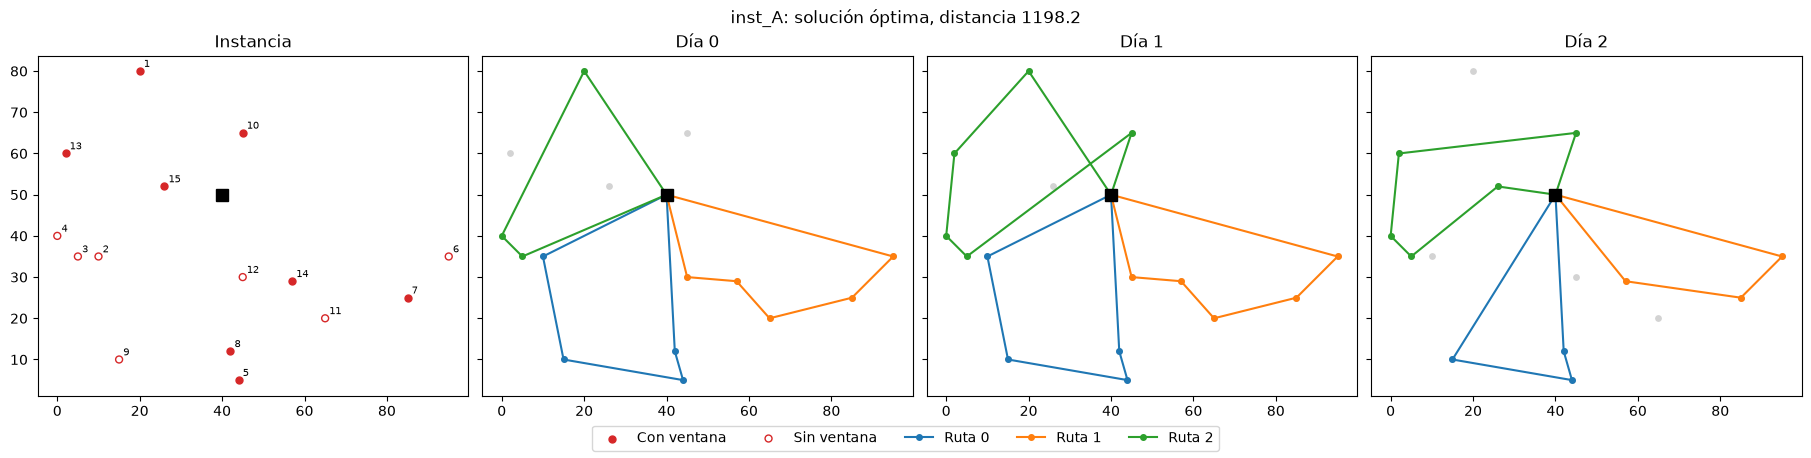

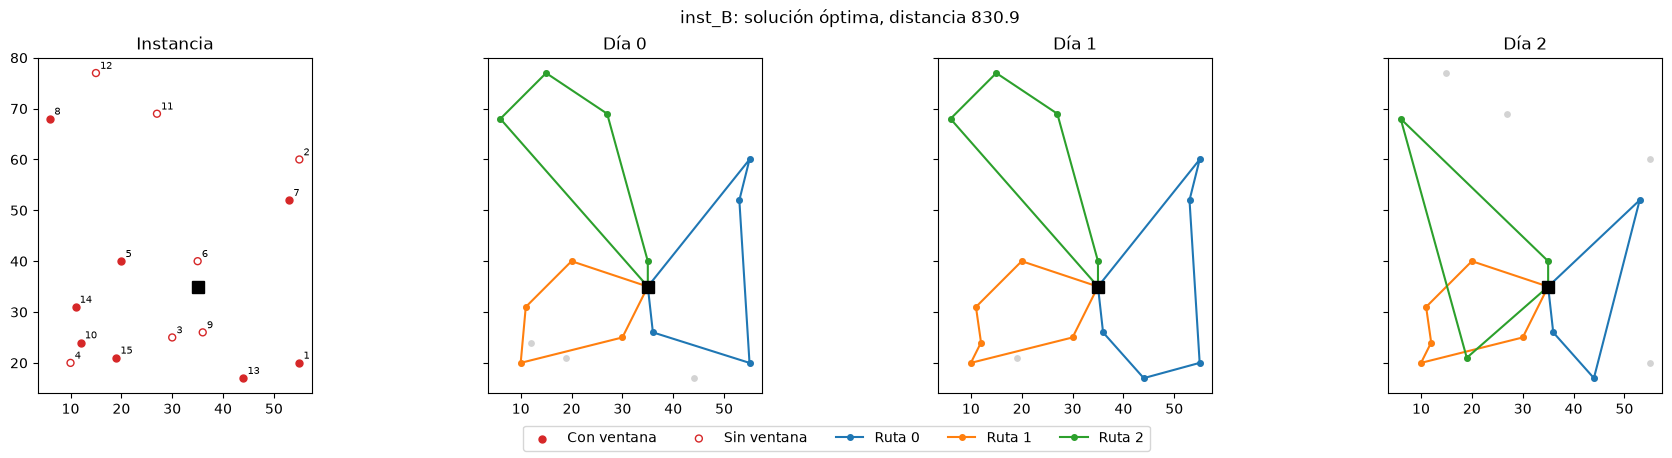

In [11]:
graficar_rutas(m_A, sol_A)
graficar_rutas(m_B, sol_B)

### 7.2 Relajación continua y brecha de integralidad

### 7.3 Configuraciones del solver

#### Cuts = 0

#### Presolve = 0

#### MIPFocus = 1

#### MIPFocus = 3

#### Heuristics = 0

### 7.4 Ajuste automático de parámetros (`model.tune()`)

### 7.5 Análisis de sensibilidad de la capacidad $Q$ (`m.fixed()`)

## 8. Resumen de resultados

## 9. Discusión